In [16]:
import os, re, shutil, string, time, tarfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 1337
BATCH_SIZE = 32
keras.utils.set_random_seed(SEED)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


# Exercise 4 – NLP: Movie Review Sentiment Analysis Using TensorFlow

**Student Name:** Mukesh Manikandan  
**Student ID:** 110227192  
**Program:** Master of Applied Computing (MAC)  
**Course Exercise:** Exercise 4 – Natural Language Processing (NLP)

This notebook follows the five parts and eleven tasks specified in the Exercise 4 assignment.


In [17]:
# Get the IMDB dataset. Tries, in order:
#   1) an existing local folder  2) the Stanford server  3) the Hugging Face copy
# If you already have it from the course notebooks, set DATA_DIR to that folder
# (the one that contains train/ and test/).
DATA_DIR = "aclImdb"

def download_from_stanford():
    url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
    print("Trying Stanford server (~80 MB)...")
    tar_path, _ = urllib.request.urlretrieve(url, "aclImdb_v1.tar.gz")
    with tarfile.open(tar_path) as tar:
        tar.extractall(".")

def download_from_huggingface():
    print("Trying Hugging Face copy of IMDB...")
    try:
        from datasets import load_dataset
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "datasets"])
        from datasets import load_dataset
    ds = load_dataset("stanfordnlp/imdb")          # splits: train, test (labels: 0=neg, 1=pos)
    for split in ("train", "test"):
        for label_id, label_name in ((0, "neg"), (1, "pos")):
            os.makedirs(os.path.join("aclImdb", split, label_name), exist_ok=True)
        for i, ex in enumerate(ds[split]):
            label_name = "pos" if ex["label"] == 1 else "neg"
            path = os.path.join("aclImdb", split, label_name, f"{i}.txt")
            with open(path, "w", encoding="utf-8") as f:
                f.write(ex["text"])

if not os.path.isdir(os.path.join(DATA_DIR, "train")):
    try:
        download_from_stanford()
    except Exception as e:
        print("Stanford download failed:", repr(e))
        download_from_huggingface()
    DATA_DIR = "aclImdb"

train_dir = os.path.join(DATA_DIR, "train")
test_dir = os.path.join(DATA_DIR, "test")

# 'unsup' holds unlabeled reviews, it is not a class -> remove it
unsup_dir = os.path.join(train_dir, "unsup")
if os.path.isdir(unsup_dir):
    shutil.rmtree(unsup_dir)
print("Folders in train/:", os.listdir(train_dir))
print("Reviews per class (train):", {c: len(os.listdir(os.path.join(train_dir, c))) for c in os.listdir(train_dir)})

Folders in train/: ['pos', 'neg']
Reviews per class (train): {'pos': 12500, 'neg': 12500}


In [18]:
# 1, 2 & 3. Load the dataset (if needed) and display five reviews
import os
from tensorflow import keras

if "raw_train_ds" not in globals():
    SEED = 1337
    BATCH_SIZE = 32
    train_dir = "aclImdb/train"
    raw_train_ds = keras.utils.text_dataset_from_directory(
        train_dir, batch_size=BATCH_SIZE, validation_split=0.2,
        subset="training", seed=SEED)

class_names = raw_train_ds.class_names
for text_batch, label_batch in raw_train_ds.take(1):
    for i in range(5):
        review = text_batch.numpy()[i].decode("utf-8")
        label = int(label_batch.numpy()[i])
        print(f"Review {i + 1} | label = {label} ({class_names[label]})")
        print(review[:300] + ("..." if len(review) > 300 else ""))
        print()

Review 1 | label = 0 (neg)
Another variation and improvisation on the famous and beloved children tale, La Bete (1975) aka The Beast tries to imagine (in very graphic and what may seem offensive and disturbing but in reality rather silly and comical way), what actually happened between Beauty and the Beast? I am amused by man...

Review 2 | label = 0 (neg)
Just imagine the real Hitler, who was a master of propaganda and speech, would have been such a mumbling moron as Carlyle portrayed him in this film.<br /><br />Nobody would have followed him, not even a desperate, unemployed guy in the 1920s.<br /><br />This is just a Hollywood cardboard piece of p...

Review 3 | label = 1 (pos)
John (Ben Chaplin) is a lonely bank clerk who lives in a small town not far from London. Though the Internet, he contacts a Russian agency of brides. He selects Sophia (Nicole Kidman  the guy could be lonely and shy, but certainly has a good taste, doesn't he?) and when they met each other, he real...

Revi

In [19]:
# Create the missing validation and test datasets
from tensorflow import keras

SEED = 1337
BATCH_SIZE = 32
train_dir, test_dir = "aclImdb/train", "aclImdb/test"

raw_val_ds = keras.utils.text_dataset_from_directory(
    train_dir, batch_size=BATCH_SIZE, validation_split=0.2,
    subset="validation", seed=SEED)
raw_test_ds = keras.utils.text_dataset_from_directory(
    test_dir, batch_size=BATCH_SIZE)

Found 25000 files belonging to 2 classes.
Using 5000 files for validation.
Found 25000 files belonging to 2 classes.


In [20]:
def custom_standardization(input_data):
    """Lowercase, remove HTML tags (e.g. <br />), remove punctuation."""
    lowercase = tf.strings.lower(input_data)
    no_html = tf.strings.regex_replace(lowercase, r"<[^>]*>", " ")
    no_punct = tf.strings.regex_replace(
        no_html, "[%s]" % re.escape(string.punctuation), "")
    return no_punct

### Task 2 – Why is text preprocessing important?

Text preprocessing improves the quality and consistency of text before it is given to an NLP model. Converting text to lowercase reduces differences between words that have the same meaning but different capitalization. Removing HTML tags and punctuation removes unnecessary characters and noise. This helps the vectorizer identify useful words and patterns more consistently and can improve classification performance.


In [21]:
# Three original reviews vs processed reviews
for text_batch, _ in raw_train_ds.take(1):
    originals = text_batch[:3]
    processed = custom_standardization(originals)
    for i in range(3):
        print(f"[Original {i + 1}]\n{originals.numpy()[i].decode('utf-8')[:300]}...")
        print(f"[Processed {i + 1}]\n{processed.numpy()[i].decode('utf-8')[:300]}...")
        print("-" * 60)

[Original 1]
David Zucker has directed one of the most enjoyable comedies of the year with this goofy farce. Yes, it's a matter of acquired taste and depends upon a wealth of sophomoric gags, but it is consistently funny throughout unlike some recent comedic efforts. The film is loaded with all kinds of jokes ra...
[Processed 1]
david zucker has directed one of the most enjoyable comedies of the year with this goofy farce yes its a matter of acquired taste and depends upon a wealth of sophomoric gags but it is consistently funny throughout unlike some recent comedic efforts the film is loaded with all kinds of jokes ranging...
------------------------------------------------------------
[Original 2]
This is the biggest load of crap that I have seen in a long time. The last time I hated a movie so much was whilst watching "28 Days later" and "Magnolia". There is absolutely no point to this movie, except to see some really sick and twisted sex/rape scenes, Gillian Anderson relieving hers

In [22]:
# Text-only dataset (used to adapt the vectorization layers)
train_text_ds = raw_train_ds.map(lambda x, y: x)

def plot_history(history, title):
    acc, val_acc = history.history["accuracy"], history.history["val_accuracy"]
    loss, val_loss = history.history["loss"], history.history["val_loss"]
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(6, 4))
    plt.plot(epochs, acc, "bo-", label="Training accuracy")
    plt.plot(epochs, val_acc, "r^-", label="Validation accuracy")
    plt.title(f"{title} - Accuracy")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.grid(alpha=.3)
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.plot(epochs, loss, "bo-", label="Training loss")
    plt.plot(epochs, val_loss, "r^-", label="Validation loss")
    plt.title(f"{title} - Loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=.3)
    plt.show()

def overfitting_report(history):
    acc, val_acc = history.history["accuracy"][-1], history.history["val_accuracy"][-1]
    loss, val_loss = history.history["loss"][-1], history.history["val_loss"][-1]
    best_val_epoch = int(np.argmin(history.history["val_loss"])) + 1
    total = len(history.history["val_loss"])
    gap = acc - val_acc
    print(f"Final train acc = {acc:.4f} | final val acc = {val_acc:.4f} | gap = {gap:.4f}")
    print(f"Final train loss = {loss:.4f} | final val loss = {val_loss:.4f}")
    print(f"Lowest validation loss at epoch {best_val_epoch} of {total}")
    overfit = best_val_epoch < total and gap > 0.03
    if overfit:
        print("-> Signs of overfitting: validation loss stopped improving / rose while training accuracy kept increasing.")
    elif gap > 0.05:
        print("-> Mild overfitting: training accuracy is noticeably higher than validation accuracy.")
    else:
        print("-> No strong overfitting: training and validation curves stay close.")
    return gap, overfit

In [23]:
MAX_TOKENS_NGRAM = 15000

text_vectorization_ngram = layers.TextVectorization(
    max_tokens=MAX_TOKENS_NGRAM,
    ngrams=2,                 # unigrams + bigrams
    output_mode="tf_idf",
    standardize=custom_standardization,
)

# 1. Adapt on the training dataset
text_vectorization_ngram.adapt(train_text_ds)

### Task 3 – Unigram and bigram representations

A **unigram** represents each individual word as a separate feature. For example, the sentence “this movie is good” contains the unigrams “this”, “movie”, “is”, and “good”.

A **bigram** represents each consecutive pair of words as a feature. The same sentence contains “this movie”, “movie is”, and “is good”.

Unigrams capture individual word information, while bigrams can capture short phrases and some context between neighboring words. Using both allows the model to use individual terms as well as two-word expressions.


In [24]:
# 2. First 20 vocabulary entries
vocab_ngram = [str(w) for w in text_vectorization_ngram.get_vocabulary()]
print("Vocabulary size:", len(vocab_ngram))
print("First 20 entries:", vocab_ngram[:20])

Vocabulary size: 15000
First 20 entries: ['[UNK]', 'the', 'and', 'a', 'of', 'to', 'is', 'in', 'it', 'i', 'this', 'that', 'was', 'as', 'with', 'for', 'movie', 'but', 'of the', 'film']


In [25]:
# 3. Three reviews as TF-IDF vectors
for text_batch, _ in raw_train_ds.take(1):
    sample_tfidf = text_vectorization_ngram(text_batch[:3]).numpy()
    for i in range(3):
        top_idx = np.argsort(sample_tfidf[i])[::-1][:5]
        print(f"Review {i + 1}: vector shape = {sample_tfidf[i].shape}, "
              f"non-zero entries = {np.count_nonzero(sample_tfidf[i])}")
        print("  Top 5 TF-IDF terms:",
              [(vocab_ngram[j], round(float(sample_tfidf[i][j]), 3)) for j in top_idx])

Review 1: vector shape = (15000,), non-zero entries = 337
  Top 5 TF-IDF terms: [('[UNK]', 1324.518), ('the sky', 28.222), ('sky', 24.089), ('castle', 19.628), ('the', 13.944)]
Review 2: vector shape = (15000,), non-zero entries = 135
  Top 5 TF-IDF terms: [('[UNK]', 389.267), ('ruin the', 5.863), ('had this', 5.829), ('given it', 5.779), ('later i', 5.779)]
Review 3: vector shape = (15000,), non-zero entries = 176
  Top 5 TF-IDF terms: [('[UNK]', 889.753), ('for best', 31.09), ('costume', 23.999), ('best', 18.127), ('design', 17.806)]


In [26]:
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(ds, vectorizer):
    return ds.map(lambda x, y: (vectorizer(x), y),
                  num_parallel_calls=AUTOTUNE).cache().prefetch(AUTOTUNE)

ngram_train_ds = make_ds(raw_train_ds, text_vectorization_ngram)
ngram_val_ds = make_ds(raw_val_ds, text_vectorization_ngram)
ngram_test_ds = make_ds(raw_test_ds, text_vectorization_ngram)

In [27]:
def get_ngram_model():
    inputs = keras.Input(shape=(len(vocab_ngram),))   # 15,000 features on the full IMDB data
    x = layers.Dense(32, activation="relu")(inputs)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0001),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

ngram_model = get_ngram_model()
ngram_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 15000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       480,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 480,065 (1.83 MB)

 Trainable params: 480,065 (1.83 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
start = time.time()
ngram_history = ngram_model.fit(
    ngram_train_ds, validation_data=ngram_val_ds, epochs=10, verbose=2)
ngram_time = time.time() - start
print(f"\nN-gram training time: {ngram_time:.1f} s")

Epoch 1/10
625/625 - 10s - 15ms/step - accuracy: 0.6803 - loss: 0.9398 - val_accuracy: 0.8466 - val_loss: 0.4336
Epoch 2/10
625/625 - 4s - 6ms/step - accuracy: 0.8419 - loss: 0.4004 - val_accuracy: 0.8826 - val_loss: 0.3362
Epoch 3/10
625/625 - 4s - 6ms/step - accuracy: 0.8838 - loss: 0.3135 - val_accuracy: 0.8922 - val_loss: 0.2935
Epoch 4/10
625/625 - 4s - 7ms/step - accuracy: 0.9085 - loss: 0.2561 - val_accuracy: 0.8960 - val_loss: 0.2755
Epoch 5/10
625/625 - 4s - 6ms/step - accuracy: 0.9269 - loss: 0.2134 - val_accuracy: 0.8932 - val_loss: 0.2755
Epoch 6/10
625/625 - 4s - 7ms/step - accuracy: 0.9397 - loss: 0.1803 - val_accuracy: 0.8976 - val_loss: 0.2645
Epoch 7/10
625/625 - 5s - 7ms/step - accuracy: 0.9493 - loss: 0.1547 - val_accuracy: 0.8906 - val_loss: 0.2857
Epoch 8/10
625/625 - 4s - 6ms/step - accuracy: 0.9607 - loss: 0.1286 - val_accuracy: 0.8962 - val_loss: 0.2785
Epoch 9/10
625/625 - 4s - 7ms/step - accuracy: 0.9676 - loss: 0.1093 - val_accuracy: 0.8964 - val_loss: 0.2782

In [29]:
ngram_test_loss, ngram_test_acc = ngram_model.evaluate(ngram_test_ds, verbose=0)
print(f"N-Gram test loss: {ngram_test_loss:.4f} | test accuracy: {ngram_test_acc:.4f}")

N-Gram test loss: 0.2876 | test accuracy: 0.8970


In [30]:
print(f"Final N-Gram test accuracy: {ngram_test_acc:.4f}\n")
ngram_gap, ngram_overfit = overfitting_report(ngram_history)

Final N-Gram test accuracy: 0.8970

Final train acc = 0.9682 | final val acc = 0.8996 | gap = 0.0685
Final train loss = 0.0978 | final val loss = 0.2841
Lowest validation loss at epoch 6 of 10
-> Signs of overfitting: validation loss stopped improving / rose while training accuracy kept increasing.


In [31]:
MAX_TOKENS_SEQ = 10000
MAX_LENGTH = 200

text_vectorization_seq = layers.TextVectorization(
    max_tokens=MAX_TOKENS_SEQ,
    output_mode="int",
    output_sequence_length=MAX_LENGTH,
    standardize=custom_standardization,
)

# 1. Adapt on the training dataset
text_vectorization_seq.adapt(train_text_ds)

In [32]:
# 2. First 20 vocabulary entries
vocab_seq = [str(w) for w in text_vectorization_seq.get_vocabulary()]
print("Vocabulary size:", len(vocab_seq))
print("First 20 entries:", vocab_seq[:20])

Vocabulary size: 10000
First 20 entries: ['', '[UNK]', 'the', 'and', 'a', 'of', 'to', 'is', 'in', 'it', 'i', 'this', 'that', 'was', 'as', 'with', 'for', 'movie', 'but', 'film']


In [33]:
# 3. Three reviews as integer sequences
for text_batch, _ in raw_train_ds.take(1):
    sample_seq = text_vectorization_seq(text_batch[:3]).numpy()
    for i in range(3):
        print(f"Review {i + 1}: shape = {sample_seq[i].shape}")
        print("  First 30 token ids:", sample_seq[i][:30].tolist())

Review 1: shape = (200,)
  First 30 token ids: [130, 457, 23, 225, 18, 2, 612, 3096, 34, 23, 4, 906, 753, 5, 6732, 1, 36, 22, 174, 6, 66, 74, 237, 15, 1, 34, 23, 37, 5442, 12]
Review 2: shape = (200,)
  First 30 token ids: [11, 7, 28, 5, 2, 88, 215, 95, 10, 25, 121, 104, 10, 114, 2, 9661, 234, 5, 11, 17, 2, 17, 7, 52, 813, 3, 843, 11, 179, 6]
Review 3: shape = (200,)
  First 30 token ids: [193, 205, 77, 4, 85, 332, 5, 2349, 1658, 3, 205, 75, 26, 16, 88, 5, 48, 27, 115, 8, 2, 500, 18, 62, 4, 1854, 1645, 99, 2850, 86]


In [34]:
seq_train_ds = make_ds(raw_train_ds, text_vectorization_seq)
seq_val_ds = make_ds(raw_val_ds, text_vectorization_seq)
seq_test_ds = make_ds(raw_test_ds, text_vectorization_seq)

In [35]:
def get_sequence_model():
    inputs = keras.Input(shape=(MAX_LENGTH,), dtype="int64")
    x = layers.Embedding(input_dim=MAX_TOKENS_SEQ, output_dim=32)(inputs)
    x = layers.Conv1D(64, 3, activation="relu")(x)
    x = layers.GlobalAveragePooling1D()(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0001),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

seq_model = get_sequence_model()
seq_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 200, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 198, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

In [36]:
start = time.time()
seq_history = seq_model.fit(
    seq_train_ds, validation_data=seq_val_ds, epochs=15, verbose=2)
seq_time = time.time() - start
print(f"\nSequence model training time: {seq_time:.1f} s")

Epoch 1/15
625/625 - 10s - 17ms/step - accuracy: 0.5978 - loss: 0.6881 - val_accuracy: 0.6444 - val_loss: 0.6715
Epoch 2/15
625/625 - 8s - 12ms/step - accuracy: 0.7464 - loss: 0.6193 - val_accuracy: 0.7738 - val_loss: 0.5565
Epoch 3/15
625/625 - 8s - 12ms/step - accuracy: 0.8234 - loss: 0.4910 - val_accuracy: 0.8328 - val_loss: 0.4489
Epoch 4/15
625/625 - 10s - 17ms/step - accuracy: 0.8526 - loss: 0.4009 - val_accuracy: 0.8530 - val_loss: 0.3900
Epoch 5/15
625/625 - 7s - 11ms/step - accuracy: 0.8695 - loss: 0.3483 - val_accuracy: 0.8608 - val_loss: 0.3572
Epoch 6/15
625/625 - 8s - 13ms/step - accuracy: 0.8810 - loss: 0.3145 - val_accuracy: 0.8660 - val_loss: 0.3373
Epoch 7/15
625/625 - 7s - 12ms/step - accuracy: 0.8904 - loss: 0.2900 - val_accuracy: 0.8692 - val_loss: 0.3242
Epoch 8/15
625/625 - 10s - 17ms/step - accuracy: 0.8974 - loss: 0.2709 - val_accuracy: 0.8724 - val_loss: 0.3152
Epoch 9/15
625/625 - 9s - 15ms/step - accuracy: 0.9046 - loss: 0.2550 - val_accuracy: 0.8748 - val_lo

In [37]:
seq_test_loss, seq_test_acc = seq_model.evaluate(seq_test_ds, verbose=0)
print(f"Sequence model test loss: {seq_test_loss:.4f} | test accuracy: {seq_test_acc:.4f}")

Sequence model test loss: 0.3322 | test accuracy: 0.8634


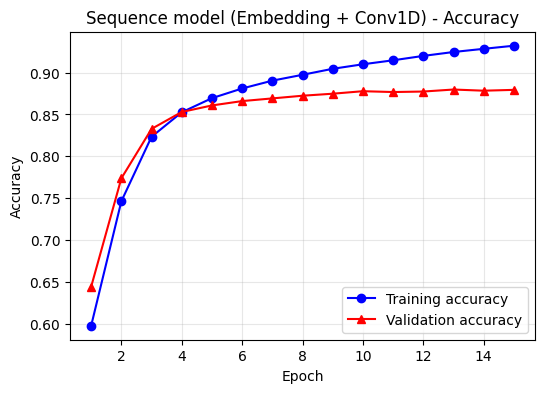

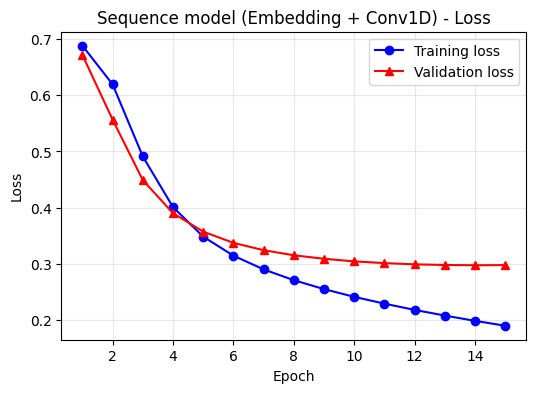

In [38]:
plot_history(seq_history, "Sequence model (Embedding + Conv1D)")

In [39]:
print(f"Sequence model test accuracy: {seq_test_acc:.4f}\n")
seq_gap, seq_overfit = overfitting_report(seq_history)

Sequence model test accuracy: 0.8634

Final train acc = 0.9321 | final val acc = 0.8794 | gap = 0.0527
Final train loss = 0.1898 | final val loss = 0.2977
Lowest validation loss at epoch 14 of 15
-> Signs of overfitting: validation loss stopped improving / rose while training accuracy kept increasing.


In [40]:
rows = [
    ("Text representation", "TF-IDF", "Integer sequences"),
    ("Vocabulary size", "15,000", "10,000"),
    ("Model architecture", "Dense network", "Embedding + Conv1D"),
    ("Training accuracy", f"{ngram_history.history['accuracy'][-1]:.4f}",
     f"{seq_history.history['accuracy'][-1]:.4f}"),
    ("Validation accuracy", f"{ngram_history.history['val_accuracy'][-1]:.4f}",
     f"{seq_history.history['val_accuracy'][-1]:.4f}"),
    ("Test accuracy", f"{ngram_test_acc:.4f}", f"{seq_test_acc:.4f}"),
    ("Training time", f"{ngram_time:.1f} s", f"{seq_time:.1f} s"),
    ("Signs of overfitting",
     f"{'Yes' if ngram_overfit else 'No/mild'} (gap {ngram_gap:.3f})",
     f"{'Yes' if seq_overfit else 'No/mild'} (gap {seq_gap:.3f})"),
]
w0 = max(len(r[0]) for r in rows) + 2
w1 = max(len(r[1]) for r in rows) + 2
w2 = max(len(r[2]) for r in rows) + 2
print(f"{'Evaluation criteria':<{w0}}{'N-Gram Model':<{w1}}{'Sequence Model':<{w2}}")
print("-" * (w0 + w1 + w2))
for r in rows:
    print(f"{r[0]:<{w0}}{r[1]:<{w1}}{r[2]:<{w2}}")

better = "N-Gram (TF-IDF) model" if ngram_test_acc >= seq_test_acc else "Sequence (Embedding + Conv1D) model"
print(f"\nBetter model by test accuracy: {better}")

Evaluation criteria   N-Gram Model     Sequence Model      
-----------------------------------------------------------
Text representation   TF-IDF           Integer sequences   
Vocabulary size       15,000           10,000              
Model architecture    Dense network    Embedding + Conv1D  
Training accuracy     0.9682           0.9321              
Validation accuracy   0.8996           0.8794              
Test accuracy         0.8970           0.8634              
Training time         46.3 s           129.8 s             
Signs of overfitting  Yes (gap 0.069)  Yes (gap 0.053)     

Better model by test accuracy: N-Gram (TF-IDF) model


In [41]:
reviews = [
    "This movie was absolutely fantastic and entertaining.",
    "The acting was terrible and the story was boring.",
    "The movie was not bad, but it was not particularly good either.",
    "I expected a great movie, but I was disappointed.",
]
review_tensor = tf.constant(reviews)

# 1. Predict with both models
p_ngram = ngram_model.predict(text_vectorization_ngram(review_tensor), verbose=0).ravel()
p_seq = seq_model.predict(text_vectorization_seq(review_tensor), verbose=0).ravel()

label_of = lambda p: "Positive" if p >= 0.5 else "Negative"

print(f"{'#':<3}{'N-Gram prob':<13}{'N-Gram':<10}{'Seq prob':<11}{'Sequence':<10}{'Agree?':<7}")
for i, r in enumerate(reviews):
    a, b = float(p_ngram[i]), float(p_seq[i])
    print(f"{i + 1:<3}{a:<13.4f}{label_of(a):<10}{b:<11.4f}{label_of(b):<10}"
          f"{'Yes' if label_of(a) == label_of(b) else 'NO':<7}")
    print(f'   "{r}"')

#  N-Gram prob  N-Gram    Seq prob   Sequence  Agree? 
1  0.8754       Positive  0.7305     Positive  Yes    
   "This movie was absolutely fantastic and entertaining."
2  0.0838       Negative  0.1676     Negative  Yes    
   "The acting was terrible and the story was boring."
3  0.3280       Negative  0.2548     Negative  Yes    
   "The movie was not bad, but it was not particularly good either."
4  0.6224       Positive  0.5934     Positive  Yes    
   "I expected a great movie, but I was disappointed."


In [42]:
# 2 & 3. Compare and find disagreements
diff = [i + 1 for i in range(len(reviews)) if label_of(p_ngram[i]) != label_of(p_seq[i])]
print("Reviews where the two models disagree:", diff if diff else "none")

Reviews where the two models disagree: none
